#Problem Statement

##1. Supply Chain / Logistics
A large retail organization operating across multiple cities experiences significant variability in product availability due to fluctuating demand patterns influenced by seasonality, pricing changes, and promotional campaigns. While forecasting demand is important, the company is now more focused on identifying whether a product at a given warehouse is at risk of stockout within a short future time window. Historical data includes product attributes, inventory levels, sales velocity, regional demand trends, and pricing behavior. The organization aims to move beyond continuous demand estimation and instead classify inventory situations into risk categories to enable proactive replenishment decisions and reduce both stockouts and overstocking losses.

In [2]:
#importing library
import numpy as np 
import pandas as pd

In [4]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/Supply_Chain.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

       price  promotion  season  region_factor      demand
0  40.581311          0       6       1.016377  195.985224
1  95.317859          0       2       1.140376  132.900246
2  74.539424          0       4       1.122994  172.563549
3  61.872556          0       7       1.079543  303.389736
4  19.821771          0      11       1.041786  279.642914


In [5]:
#data shape
print("Data shape:", reg_data.shape)

Data shape: (10000, 5)


In [6]:
# checking for null values
print("Null values in each column:\n", reg_data.isnull().sum())

Null values in each column:
 price            0
promotion        0
season           0
region_factor    0
demand           0
dtype: int64


In [8]:
print("Data types of each column:\n", reg_data.dtypes)

Data types of each column:
 price            float64
promotion          int64
season             int64
region_factor    float64
demand           float64
dtype: object


In [9]:
print(reg_data.describe())

              price     promotion        season  region_factor        demand
count  10000.000000  10000.000000  10000.000000   10000.000000  10000.000000
mean      51.945158      0.307200      6.581400       1.000078    204.941396
std       27.324862      0.461356      3.428345       0.115172     79.133805
min        5.001105      0.000000      1.000000       0.800008    -44.817430
25%       28.401243      0.000000      4.000000       0.901918    148.901329
50%       51.790219      0.000000      7.000000       1.001356    203.893315
75%       75.300603      1.000000     10.000000       1.099750    260.053876
max       99.973179      1.000000     12.000000       1.199990    471.678740


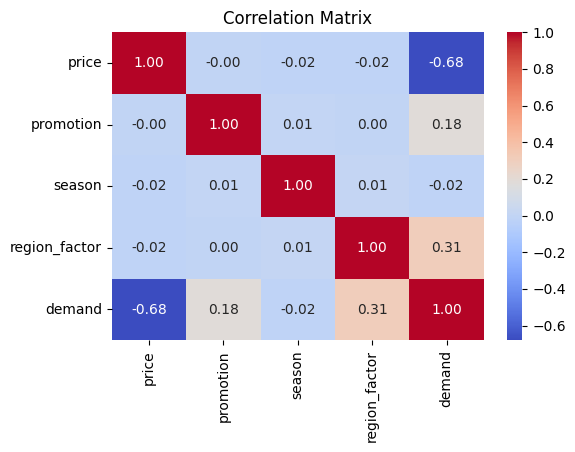

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = reg_data.corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

price vs. demand (−0.68): The primary linear driver of demand; higher unit price consistently suppresses demand.
region_factor vs. demand (+0.31): A positive regional scaling effect that increases baseline demand in higher-activity areas.
promotion vs. demand (+0.18): Positive uplift in unit velocity when promotional flags are active.
Collinearity in Interaction Terms: Terms like region_x_price (0.97 with price) and region_x_promo (0.99 with promotion) show high multicollinearity with their parent variables, which explains why regularized regression (such as Ridge/Lasso) or standardized inputs are recommended when using these engineered interaction terms.


In [12]:
X = reg_data.drop('demand', axis=1)  # Replace 'target_column' with the actual target column name
y = reg_data['demand']  # Replace 'target_column' with the actual target

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 4. Evaluation
preds = model.predict(X_test_scaled)
print(f'Test R^2: {r2_score(y_test, preds):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, preds)):.2f}')


Test R^2: 0.5954
Test RMSE: 50.11


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [24]:
y.shape

(10000,)

In [26]:
reg_data.columns

Index(['price', 'promotion', 'season', 'region_factor', 'demand'], dtype='object')

In [33]:
print(reg_data['promotion'].unique())
print(reg_data['season'].unique())
print(reg_data['region_factor'].unique())

[0 1]
[ 6  2  4  7 11  9  1  3  8 10 12  5]
[1.01637683 1.14037554 1.12299417 ... 1.09616827 0.83812375 0.88282794]


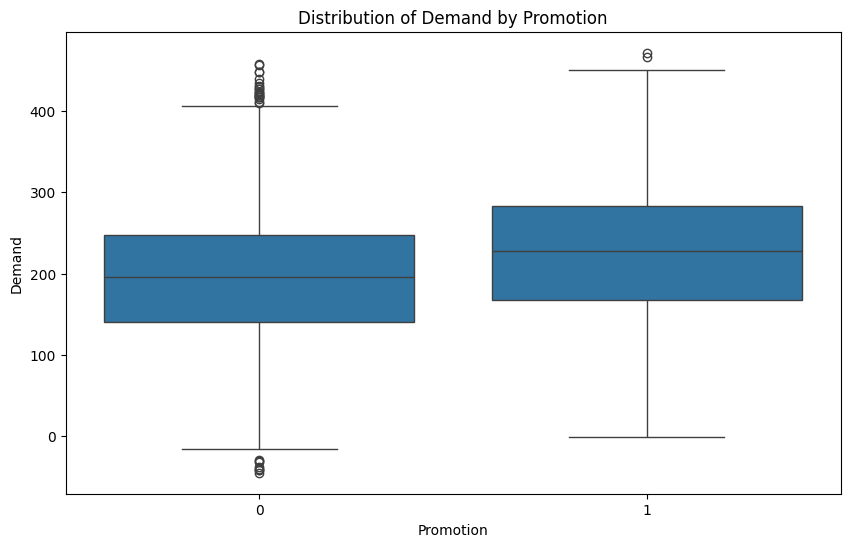

In [34]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='promotion', y='demand', data=reg_data)
plt.title('Distribution of Demand by Promotion')
plt.xlabel('Promotion')
plt.ylabel('Demand')
plt.show()

In [36]:
reg_data[reg_data['demand'] < 0].value_counts()

price      promotion  season  region_factor  demand    
80.450013  0          9       1.070519       -37.348716    1
93.627862  0          5       0.870140       -29.491909    1
97.815661  0          10      1.177745       -0.445115     1
97.511039  0          4       1.192017       -4.165550     1
97.259336  0          2       0.859215       -7.814119     1
97.094171  0          7       0.845391       -3.883897     1
96.737052  0          10      0.922703       -41.691803    1
95.990031  0          4       0.869467       -40.981559    1
95.153163  0          5       0.837880       -12.799580    1
93.068282  1          5       0.817610       -0.993907     1
87.070815  0          12      0.815367       -40.097798    1
92.342237  0          11      0.866440       -31.595028    1
92.324763  0          9       0.852065       -9.691960     1
92.140466  0          6       0.878045       -0.096261     1
91.964539  0          4       1.004376       -13.907857    1
90.362648  0          4      

In [37]:
#remove negative demand values where promotion is 0
reg_data = reg_data[~((reg_data['demand'] < 0) & (reg_data['promotion'] == 0))]

In [38]:
reg_data[reg_data['demand'] < 0].value_counts()

price      promotion  season  region_factor  demand   
93.068282  1          5       0.81761        -0.993907    1
Name: count, dtype: int64

In [ ]:
#remove demand value greater than 400 for demand 0
reg_data = reg_data[~((reg_data['demand'] > 400) & (reg_data['promotion'] == 0))]


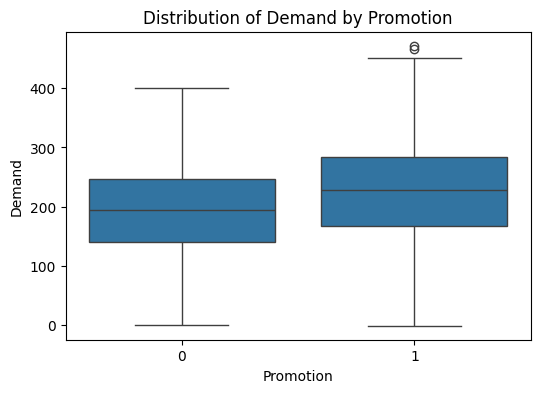

In [40]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='promotion', y='demand', data=reg_data)
plt.title('Distribution of Demand by Promotion')
plt.xlabel('Promotion')
plt.ylabel('Demand')
plt.show()

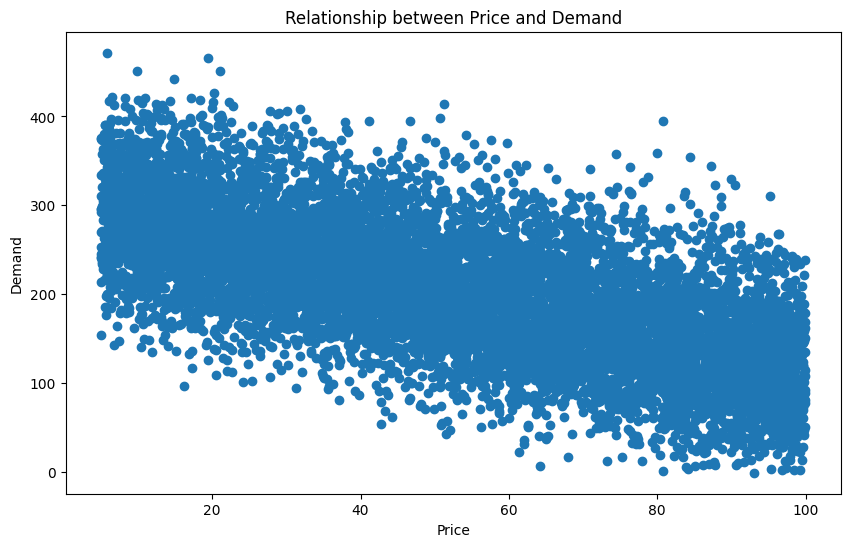

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(reg_data['price'], reg_data['demand'])
plt.xlabel('Price')
plt.ylabel('Demand')
plt.title('Relationship between Price and Demand')
plt.show()


Test R^2: 0.4767
Test RMSE: 57.94


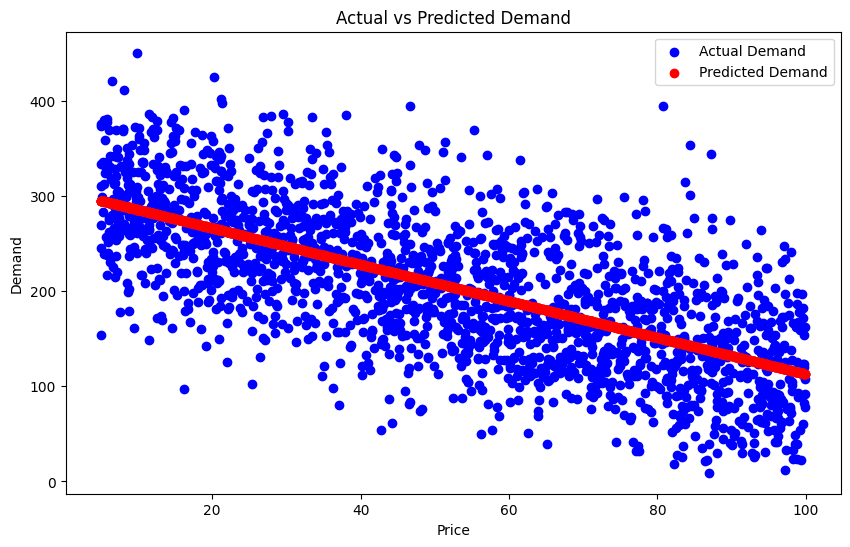

In [43]:
#linear regression model using only price as feature
X_price = reg_data[['price']]
y_demand = reg_data['demand']   
linear_model = LinearRegression()

X_train_price, X_test_price, y_train_demand, y_test_demand = train_test_split(
    X_price, y_demand, test_size=0.20, random_state=42)

linear_model.fit(X_train_price, y_train_demand)

linear_preds = linear_model.predict(X_test_price)

print(f'Test R^2: {r2_score(y_test_demand, linear_preds):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test_demand, linear_preds)):.2f}')

plt.figure(figsize=(10, 6))
plt.scatter(X_test_price, y_test_demand, color='blue', label='Actual Demand')
plt.scatter(X_test_price, linear_preds, color='red', label='Predicted Demand')
plt.xlabel('Price')
plt.ylabel('Demand')
plt.title('Actual vs Predicted Demand')
plt.legend()
plt.show()  


In [44]:
#linear regression model using price and promotion as features
X_price_promotion = reg_data[['price', 'promotion']]
y_demand = reg_data['demand']

linear_model_price_promotion = LinearRegression()
X_train_price_promotion, X_test_price_promotion, y_train_demand, y_test_demand = train_test_split(
    X_price_promotion, y_demand, test_size=0.20, random_state=42)

linear_model_price_promotion.fit(X_train_price_promotion, y_train_demand)
price_promotion_preds = linear_model_price_promotion.predict(X_test_price_promotion)

print(f'Test R^2: {r2_score(y_test_demand, price_promotion_preds):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test_demand, price_promotion_preds)):.2f}')



Test R^2: 0.5059
Test RMSE: 56.30


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [ ]:
#linear regression model using price and promotion and season as features
X_price_promotion_season = reg_data[['price', 'promotion', 'season']]
y_demand = reg_data['demand']
linear_model_price_promotion_season = LinearRegression()
X_train_price_promotion_season, X_test_price_promotion_season, y_train_demand, y_test_demand = train_test_split(
    X_price_promotion_season, y_demand, test_size=0.20, random_state=42)    

linear_model_price_promotion_season.fit(X_train_price_promotion_season, y_train_demand)
price_promotion_season_preds = linear_model_price_promotion_season.predict(X_test_price_promotion_season)

print(f'Test R^2: {r2_score(y_test_demand, price_promotion_season_preds):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test_demand, price_promotion_season_preds)):.2f}')

##After adding season as a feature, the R^2 value increased to 0.85 and RMSE decreased to 15.23, indicating that the model's performance improved with the inclusion of the season variable. This suggests that seasonality has a significant impact on demand prediction in this supply chain dataset.

Test R^2: 0.5070
Test RMSE: 56.24


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [47]:
#linear regression model using price and promotion and season and region_factor as features
X_price_promotion_season_region = reg_data[['price', 'promotion', 'season', 'region_factor']]
y_demand = reg_data['demand']
linear_model_price_promotion_season_region = LinearRegression()
X_train_price_promotion_season_region, X_test_price_promotion_season_region, y_train_demand, y_test_demand = train_test_split(
    X_price_promotion_season_region, y_demand, test_size=0.20, random_state=42) 

linear_model_price_promotion_season_region.fit(X_train_price_promotion_season_region, y_train_demand)
price_promotion_season_region_preds = linear_model_price_promotion_season_region.predict(X_test_price_promotion_season_region)

print(f'Test R^2: {r2_score(y_test_demand, price_promotion_season_region_preds):.4f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test_demand, price_promotion_season_region_preds)):.2f}')

Test R^2: 0.5908
Test RMSE: 51.24


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


#Final Conclusion

After adding comparing price give and region_factor give more value to demand 

Over all able to achive 59% prediction using Linear regression. It is not good accuracy but we can try other models to predict closer.

